# Chapitre 9 - Exercices 9.1 à 9.6

Ce notebook traite six exercices sur les goulots, les métriques et la compression :

- **9.1** : classer des opérations sur le roofline d'un H100 et de notre RTX ;
- **9.2** : calculer MBU et MFU, de l'exemple papier à la mesure sur GPU ;
- **9.3** : percentiles, SLO et goodput d'un serveur simulé selon la charge ;
- **9.4** : coût par million de tokens, auto-hébergement contre API ;
- **9.5** : dimensionner un service pour Llama 3-70B ;
- **9.6** : quantification par groupes, symétrique ou asymétrique, et vitesse attendue.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch09_inference as inf
from aie.ch02_modeles import KNOWN_CONFIGS, count_params_config, kv_cache_bytes, plain_log_axis
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore")
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)
H100, RTX = inf.ACCELERATORS["H100 SXM"], inf.ACCELERATORS["RTX 5070 Laptop"]

## Exercice 9.1 : Classer des opérations sur le roofline

**Énoncé.** Pour chacune des opérations suivantes, en bf16, calculer l'intensité
arithmétique et dire si elle est limitée par le calcul ou par la bande passante sur un
H100 SXM (989 TFLOP/s, 3,35 To/s) et sur la RTX 5070 Laptop (environ 57 TFLOP/s, 384 Go/s).
Donner le temps minimal de chacune sur H100.

1. Addition résiduelle de deux tenseurs $(4096 \times 8192)$ ;
2. projection $W_Q$ ($8192 \times 8192$) d'un token en decode ;
3. la même projection appliquée à un lot de 64 tokens en decode ;
4. la même projection pendant le prefill d'un prompt de 4096 tokens ;
5. les scores d'attention $q K^\top$ d'**un** token en decode contre un cache de 8192
   clés de dimension 128 (une tête).

**Rappels.** Intensité $I = \text{FLOPs}/\text{octets}$ ; point d'équilibre
$I^* = \pi/\beta$ ; temps minimal $\max(\text{FLOPs}/\pi, \text{octets}/\beta)$ (cours 1,
section 2, et section *Computational bottlenecks* du livre). Un produit $(m \times k)(k \times n)$
fait $2mkn$ FLOPs et déplace au moins $2(mk + kn + mn)$ octets en bf16.

**Solution.**

1. Addition : $n = 4096 \cdot 8192 \approx 3{,}4 \cdot 10^7$ additions, $3 \times 2n$ octets
   (deux lectures, une écriture) : $I = 1/6$. Très limité par la mémoire.
2. Decode, 1 token : $(1 \times 8192)(8192 \times 8192)$, $I \approx 1$ : mémoire.
3. 64 tokens : $I \approx \frac{64 \cdot 8192^2}{8192^2 + 2 \cdot 64 \cdot 8192} \approx 63$ :
   toujours sous les deux points d'équilibre (environ 150 et 295), donc mémoire, mais 63 fois
   plus de travail pour (presque) le même temps.
4. Prefill de 4096 tokens : $I = \frac{4096 \cdot 8192^2}{8192^2 + 2 \cdot 4096 \cdot 8192}
   = \frac{4096 \cdot 8192}{8192 + 8192} = 2048$ : limité par le calcul.
5. Scores en decode : $(1 \times 128)(128 \times 8192)$ : on lit tout le cache de clés
   ($2 \cdot 128 \cdot 8192$ octets) pour $2 \cdot 128 \cdot 8192$ FLOPs : $I \approx 1$.
   L'attention en decode est, elle aussi, limitée par la mémoire, et son coût croît avec
   le contexte. $\blacksquare$

In [2]:
ops = {"1. addition résiduelle": (4096 * 8192, 3 * 2 * 4096 * 8192),
       "2. W_Q, decode 1 token": (inf.matmul_flops(1, 8192, 8192), inf.matmul_bytes(1, 8192, 8192)),
       "3. W_Q, decode 64 tokens": (inf.matmul_flops(64, 8192, 8192), inf.matmul_bytes(64, 8192, 8192)),
       "4. W_Q, prefill 4096": (inf.matmul_flops(4096, 8192, 8192), inf.matmul_bytes(4096, 8192, 8192)),
       "5. q K^T, cache 8192": (inf.matmul_flops(1, 128, 8192), inf.matmul_bytes(1, 128, 8192))}
rows = []
for name, (f, b) in ops.items():
    I = f / b
    rows.append({"opération": name, "intensité": I,
                 "H100": inf.bound_kind(I, H100["flops"]["bf16"], H100["bw"]),
                 "RTX": inf.bound_kind(I, RTX["flops"]["bf16"], RTX["bw"]),
                 "temps min. H100 (µs)": inf.time_lower_bound(f, b, H100["flops"]["bf16"], H100["bw"]) * 1e6})
res91 = pd.DataFrame(rows)
display(res91.style.format({"intensité": "{:.2f}", "temps min. H100 (µs)": "{:.2f}"}).hide(axis="index"))

opération,intensité,H100,RTX,temps min. H100 (µs)
1. addition résiduelle,0.17,mémoire,mémoire,60.10
"2. W_Q, decode 1 token",1.00,mémoire,mémoire,40.07
"3. W_Q, decode 64 tokens",63.02,mémoire,mémoire,40.69
"4. W_Q, prefill 4096",2048.00,calcul,calcul,555.87
"5. q K^T, cache 8192",0.99,mémoire,mémoire,0.63


**Vérification graphique.**

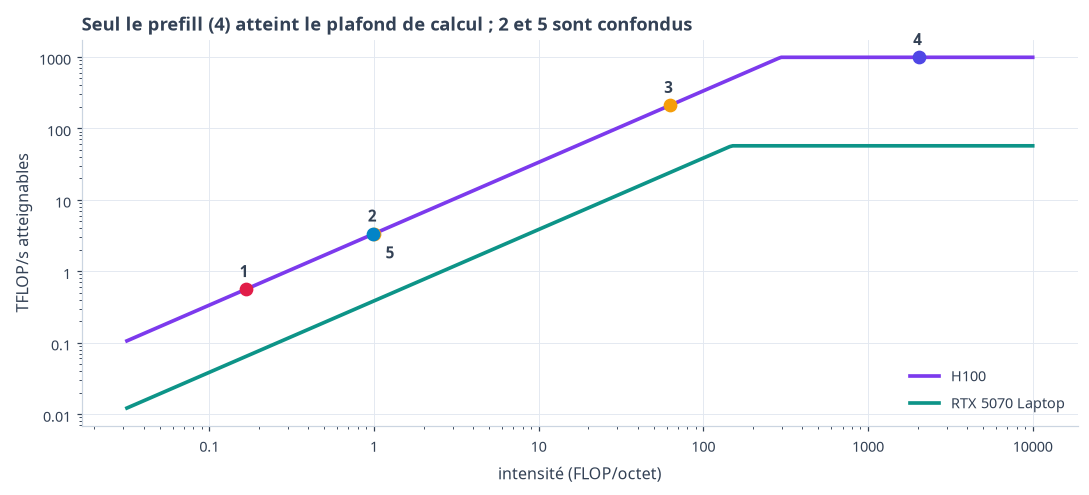

In [3]:
I_ = np.logspace(-1.5, 4, 300)
fig, ax = plt.subplots(figsize=(10, 4.6))
for name, a, c in [("H100", H100, VIOLET), ("RTX 5070 Laptop", RTX, TEAL)]:
    ax.plot(I_, inf.roofline(I_, a["flops"]["bf16"], a["bw"]) / 1e12, color=c, lw=2.4, label=name)
for k, r in res91.iterrows():
    y = float(inf.roofline(r["intensité"], H100["flops"]["bf16"], H100["bw"])) / 1e12
    ax.plot(r["intensité"], y, "o", color=[ROSE, AMBER, AMBER, INDIGO, SKY][k], ms=8)
    ax.annotate(r["opération"].split(". ")[0], (r["intensité"], y), textcoords="offset points",
                xytext=(8, -16) if k == 4 else (-4, 8), fontsize=10, fontweight="bold")
ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
ax.set_xlabel("intensité (FLOP/octet)"); ax.set_ylabel("TFLOP/s atteignables")
ax.set_title("Seul le prefill (4) atteint le plafond de calcul ; 2 et 5 sont confondus"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

> **À retenir.** En inférence, presque tout est limité par la mémoire sauf les grands
> produits du prefill : opérations élément par élément ($I < 1$), decode ($I \approx B$),
> attention en decode ($I \approx 1$ quel que soit le lot, car chaque séquence a son cache).